# 02. Two-stage anchor-based detector: Faster R-CNN
Faster R-CNN with ResNet50-FPN v2 backbone, COCO-pretrained (torchvision). The training protocol is shared with
RetinaNet (`tv_utils.py`): same frames (`data/proc/s10`), input long side 1280, horizontal flip, SGD with warmup,
12 epochs with lr x0.1 after epochs 8 and 11, mixed precision. Validation: 420 frames from 7 held-out clips,
COCO metrics with ignored regions (`common.coco_evaluate`).

In [10]:
%load_ext autoreload
%autoreload 2
import sys, subprocess
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())))

import os; os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"  
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from common import PROC, ROOT, PROJECT, CLASSES, seed_everything, write_submission, load_results
import tv_utils as tv

seed_everything()
DEVICE = "cuda"
VAL_GT = PROC / "val_gt.json"
train_ds = tv.YoloDetDataset("s10", "train", train=True)
test_df = pd.read_csv(ROOT / "test_images.csv")
COMP = "multiple-object-video-detection-hw-2-ucu-ai-2026"
print(len(train_ds), "training frames |", torch.cuda.get_device_name(0))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
2446 training frames | NVIDIA GeForce RTX 5070 Laptop GPU


In [5]:
# A few training steps with batch 2: check VRAM and time per iteration before the long run
import time
tv.set_roi_box_loss("smooth_l1")
model = tv.build_faster_rcnn().to(DEVICE)
loader = tv.make_loader(train_ds, batch_size=2, shuffle=True)
opt = torch.optim.SGD(model.parameters(), lr=1e-4, momentum=0.9)
scaler = torch.amp.GradScaler()
torch.cuda.reset_peak_memory_stats()
model.train()
times = []
for k, (imgs, targets) in zip(range(25), loader):
    t0 = time.perf_counter()
    imgs = [im.to(DEVICE) for im in imgs]
    targets = [{kk: v.to(DEVICE) for kk, v in t.items()} for t in targets]
    with torch.autocast("cuda"):
        loss = sum(model(imgs, targets).values())
    opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
    torch.cuda.synchronize(); times.append(time.perf_counter() - t0)
sec_it = np.median(times[5:])   # skip warm-up iterations
print(f"peak VRAM: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB | {sec_it:.2f} s/iter "
      f"| estimated epoch: {sec_it * len(train_ds) / 2 / 60:.1f} min")
del model, opt, loader; torch.cuda.empty_cache()

peak VRAM: 3.13 GB | 0.34 s/iter | estimated epoch: 6.8 min


## 1. Baseline
Default torchvision settings: anchors 32–512 px (one size per FPN level, ratios 0.5/1/2), 2000 RPN proposals
after NMS in training and 1000 at test time, 512 sampled RoIs per image with 25 % positives, Smooth L1 box loss.
Only the evaluation settings are changed for all runs: up to 500 detections per image, score threshold 0.001.

In [6]:
# If the kernel dies, re-run this cell with resume=True: training continues from the last finished epoch
seed_everything()
tv.set_roi_box_loss("smooth_l1")
BASE_CFG = dict(model="faster_rcnn_r50_fpn_v2", anchors="32-512", rpn_post_nms_test=1000, box_loss="smooth_l1",
                epochs=12, batch_size=2, lr=0.005, long_side=tv.LONG_SIDE, train_frames=len(train_ds))
model = tv.build_faster_rcnn()
hist_base = tv.train_detector(model, "frcnn_base", train_ds, VAL_GT, epochs=12, batch_size=2, lr=0.005,
                              warmup_iters=600, resume=True)
hist_base.to_csv(PROJECT / "results" / "frcnn_base_history.csv", index=False)

resumed from epoch 12


,name,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AP_person,AP_bicycle,AP_car,...,ms_per_image,model,anchors,rpn_post_nms_test,box_loss,epochs,batch_size,lr,long_side,train_frames
frcnn_base,frcnn_base,0.2436,0.4897,0.2179,0.1005,0.2301,0.4036,0.263,0.2327,0.4827,...,60.7,faster_rcnn_r50_fpn_v2,32-512,1000,smooth_l1,12,2,0.005,1280,2446


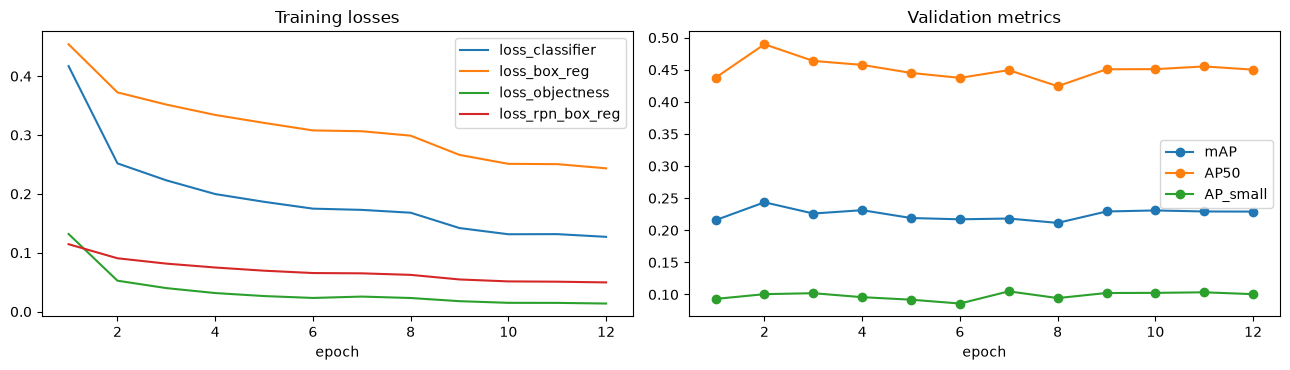

In [7]:
res_base, val_preds_base = tv.evaluate_run(model, "frcnn_base", VAL_GT, BASE_CFG)
display(pd.Series(res_base).to_frame("frcnn_base").T)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
loss_cols = [c for c in hist_base.columns if c.startswith("loss")]
hist_base.plot(x="epoch", y=loss_cols, ax=axes[0], title="Training losses")
hist_base.plot(x="epoch", y=["mAP", "AP50", "AP_small"], ax=axes[1], marker="o", title="Validation metrics")
plt.tight_layout(); plt.show()

In [ ]:
# Test predictions with the best checkpoint -> submissions/frcnn_base.csv -> Kaggle
test_preds = tv.predict(model, tv.test_items(test_df), DEVICE)
sub = write_submission(test_preds, test_df, PROJECT / "submissions" / "frcnn_base.csv")
print(sub.shape, "| mean detections per image:", round(np.mean([len(v) for v in test_preds.values()]), 1))
display(sub.head(2))
# subprocess.run(["kaggle", "competitions", "submit", "-c", COMP, "-f", str(PROJECT / "submissions" / "frcnn_base.csv"),
                # "-m", f"Faster R-CNN baseline, val mAP {res_base['mAP']:.4f}"], check=True)

In [10]:
# Restore the trained baseline (best checkpoint) and its cached validation predictions
import json, pickle
from common import CHECKPOINTS, coco_evaluate, error_analysis, best_f1_threshold, draw_boxes, save_results
model = tv.build_faster_rcnn()
model.load_state_dict(torch.load(CHECKPOINTS / "frcnn_base_best.pt", map_location=DEVICE)); model.to(DEVICE).eval()
val_preds_base = pickle.load(open(CHECKPOINTS / "frcnn_base_val_preds.pkl", "rb"))
hist_base = pd.read_csv(PROJECT / "results" / "frcnn_base_history.csv")
BASE_CFG = dict(model="faster_rcnn_r50_fpn_v2", anchors="32-512", rpn_post_nms_test=1000, box_loss="smooth_l1",
                epochs=12, batch_size=2, lr=0.005, long_side=tv.LONG_SIDE, train_frames=len(train_ds))

## 2. What the two stages contribute
The RPN proposes class-agnostic candidate boxes; its recall is the upper bound for the whole detector.
The second stage (RoI head) classifies each proposal into 8 classes + background and refines its box.
We compare RPN recall (top-N proposals, IoU >= 0.5) with the recall of the final detections.

In [12]:
rpn_tab = tv.rpn_recall(model, VAL_GT, DEVICE, top_ns=(100, 300, 1000, 2000))

# final detector recall at IoU 0.5 (class-aware, score >= 0.05), by size
gt = json.load(open(VAL_GT))
areas = np.array([a["area"] for a in gt["annotations"] if not a["iscrowd"]])
n_size = pd.Series(np.where(areas < 32**2, "small", np.where(areas < 96**2, "medium", "large"))).value_counts()
_, missed = error_analysis(VAL_GT, val_preds_base, 0.05)
final = 1 - missed.groupby("size").size().reindex(n_size.index, fill_value=0) / n_size
rpn_tab.loc["final detections (score>=0.05)"] = [*final.reindex(["small", "medium", "large"]).values,
                                                  1 - len(missed) / n_size.sum()]
display(rpn_tab)

size,small,medium,large,all
top_n,,,,
100,0.469000,0.678000,0.886000,0.670000
300,0.644000,0.819000,0.961000,0.808000
1000,0.716000,0.898000,0.997000,0.880000
2000,0.716000,0.900000,0.998000,0.881000
final detections (score>=0.05),0.541414,0.746867,0.929845,0.735745


In [11]:
# Number of RPN proposals at test time: more proposals -> more candidates in dense scenes, but slower
rows, items = [], tv.val_items(VAL_GT)
for n in [300, 1000, 2000]:
    tv.set_rpn_proposals(model, n)
    m = coco_evaluate(VAL_GT, tv.predict(model, items, DEVICE))
    rows.append({"rpn_post_nms_test": n, "mAP": m["mAP"], "AP50": m["AP50"], "AP_small": m["AP_small"],
                 "ms/img": tv.model_ms_per_image(model, items, DEVICE)})
tv.set_rpn_proposals(model, 1000)
display(pd.DataFrame(rows).round(4))

,rpn_post_nms_test,mAP,AP50,AP_small,ms/img
0,300,0.2401,0.4817,0.0991,39.4943
1,1000,0.2436,0.4897,0.1005,49.3010
2,2000,0.2443,0.4974,0.1011,64.4324


## 3. Failure analysis of the baseline
Operating point: the score threshold with the best F1 at IoU 0.5. Each detection above it is classified as
correct / ignored / duplicate / wrong class / localisation / background (simplified TIDE, Bolya et al. 2020).

best-F1 threshold 0.403 (F1 = 0.634)


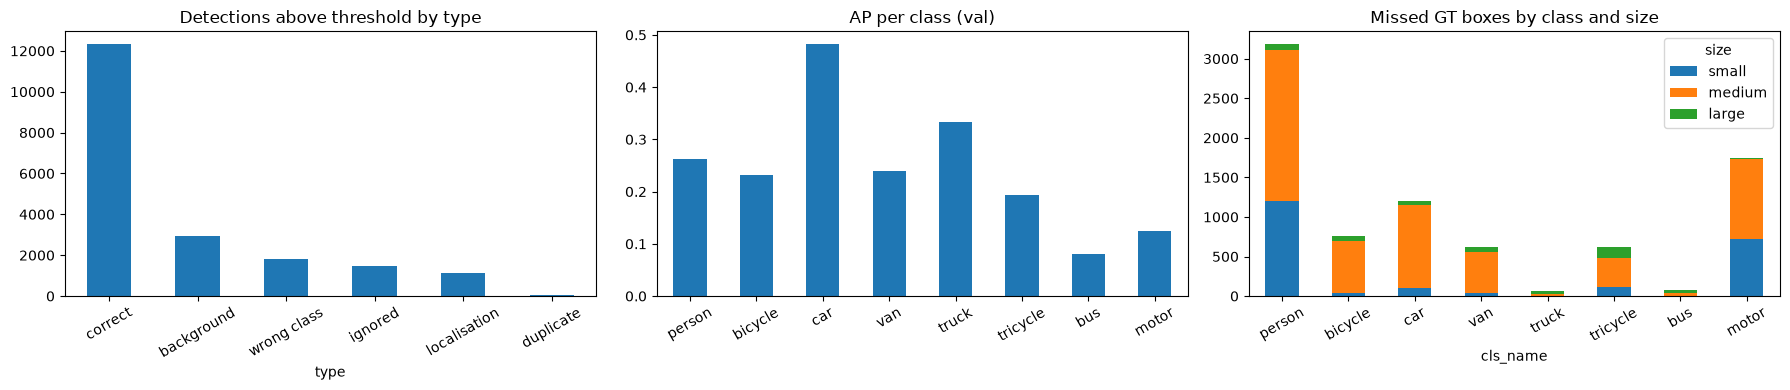

cls_name,bicycle,bus,car,motor,person,tricycle,truck,van
col_0,,,,,,,,
count,179,9,639,265,328,105,136,142


In [14]:
thr, f1 = best_f1_threshold(VAL_GT, val_preds_base)
dets, missed = error_analysis(VAL_GT, val_preds_base, thr)
print(f"best-F1 threshold {thr:.3f} (F1 = {f1:.3f})")

res_base = json.load(open(PROJECT / "results" / "frcnn_base.json"))
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
dets.type.value_counts().plot.bar(ax=axes[0], rot=30, title="Detections above threshold by type")
pd.Series({c: res_base[f"AP_{c}"] for c in CLASSES}).plot.bar(ax=axes[1], rot=30, title="AP per class (val)")
pd.crosstab(missed.cls_name, missed["size"]).reindex(CLASSES).fillna(0)[["small", "medium", "large"]] \
    .plot.bar(stacked=True, ax=axes[2], rot=30, title="Missed GT boxes by class and size")
plt.tight_layout(); plt.show()
display(pd.crosstab(dets[dets.type == "wrong class"].cls_name, "count").T)

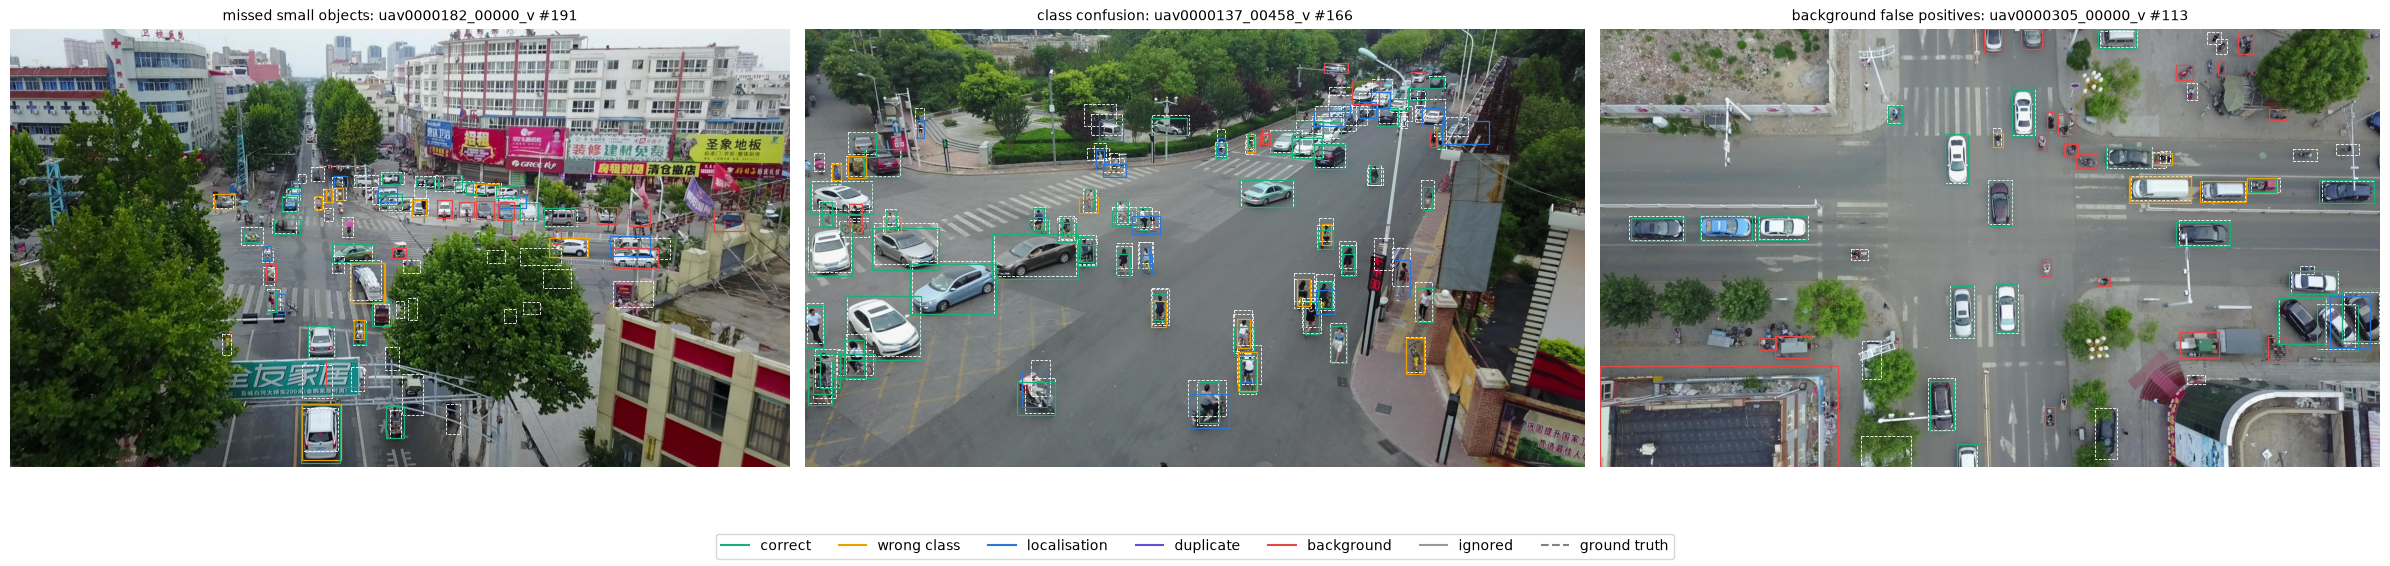

In [15]:
# Three frames: most missed small objects, most class confusions, most background false positives
TYPE_COLORS = {"correct": "#1baf7a", "wrong class": "#eda100", "localisation": "#2a78d6",
               "duplicate": "#6250d6", "background": "#e34948", "ignored": "#999999"}
id2img = {im["id"]: im for im in gt["images"]}
# pick each failure type from a different clip, so the three cases are not the same scene
cases, used = {}, set()
for title, ids in [("missed small objects", missed[missed["size"] == "small"].image_id.value_counts().index),
                   ("class confusion", dets[dets.type == "wrong class"].image_id.value_counts().index),
                   ("background false positives", dets[dets.type == "background"].image_id.value_counts().index)]:
    iid = next(i for i in ids if id2img[i]["video"] not in used)
    cases[title] = iid; used.add(id2img[iid]["video"])
    
fig, axes = plt.subplots(1, 3, figsize=(24, 6))
for ax, (title, iid) in zip(axes, cases.items()):
    im = id2img[iid]
    ax.imshow(plt.imread(ROOT / im["file_name"])); ax.axis("off")
    g = np.array([[*a["bbox"][:2], a["bbox"][0] + a["bbox"][2], a["bbox"][1] + a["bbox"][3]]
                  for a in gt["annotations"] if a["image_id"] == iid and not a["iscrowd"]]).reshape(-1, 4)
    draw_boxes(ax, g, color="white", ls="--", lw=0.6)
    p = val_preds_base[iid]; p = p[p[:, 4] >= thr]; p = p[np.argsort(-p[:, 4])]
    for b, t in zip(p, dets[dets.image_id == iid].type):      # same order as in error_analysis
        draw_boxes(ax, b[None, :4], color=TYPE_COLORS[t], lw=0.9)
    ax.set_title(f"{title}: {im['video']} #{im['frame_id']}", fontsize=10)
handles = [plt.Line2D([], [], color=c, label=t) for t, c in TYPE_COLORS.items()] + \
          [plt.Line2D([], [], color="grey", ls="--", label="ground truth")]
fig.legend(handles=handles, loc="lower center", ncol=7); plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

## 4. Experiment 1: anchor sizes from the data
Default anchors start at 32 px, but k-means on training boxes at long side 1280 gives centres from 12 to 113 px
(01_data, section 1.2). We halve all anchor sizes: (16, 32, 64, 128, 256) for P2..P6, ratios 0.5/1/2 unchanged,
so the pretrained RPN head still matches. Everything else as in the baseline.

In [16]:
del model; torch.cuda.empty_cache(); seed_everything()
tv.set_roi_box_loss("smooth_l1")
ANCH_CFG = {**BASE_CFG, "anchors": "16-256"}
model = tv.build_faster_rcnn(anchor_sizes=(16, 32, 64, 128, 256))
hist_anch = tv.train_detector(model, "frcnn_anchors", train_ds, VAL_GT, epochs=12, batch_size=2, lr=0.005,
                              warmup_iters=600, resume=True)
hist_anch.to_csv(PROJECT / "results" / "frcnn_anchors_history.csv", index=False)
res_anch, val_preds_anch = tv.evaluate_run(model, "frcnn_anchors", VAL_GT, ANCH_CFG)
# display(pd.DataFrame([res_base, res_anch]).set_index("name")[["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "ms_per_image"]])

resumed from epoch 12


In [17]:
res_base = json.load(open(PROJECT / "results" / "frcnn_base.json"))
res_anch = json.load(open(PROJECT / "results" / "frcnn_anchors.json"))
display(pd.DataFrame([res_base, res_anch]).set_index("name")[["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "ms_per_image"]])

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,ms_per_image
name,,,,,,,
frcnn_base,0.2436,0.4897,0.2179,0.1005,0.2301,0.4036,60.7
frcnn_anchors,0.2366,0.4864,0.2079,0.1000,0.2295,0.3832,49.2


## 5. Experiment 2: GIoU box loss in the second stage
Smooth L1 on box deltas treats the four coordinates independently, while the metric is IoU-based. GIoU loss
(Rezatofighi et al. 2019) optimises overlap directly and is scale-invariant, which matters for small boxes where
a 2–3 px error changes IoU a lot. Applied on top of the better anchor setting.

In [ ]:
best_anchor_run = "frcnn_anchors" if res_anch["mAP"] > res_base["mAP"] else "frcnn_base"
anchor_sizes = (16, 32, 64, 128, 256) if best_anchor_run == "frcnn_anchors" else None
del model; torch.cuda.empty_cache(); seed_everything()
tv.set_roi_box_loss("giou")
GIOU_CFG = {**(ANCH_CFG if anchor_sizes else BASE_CFG), "box_loss": "giou"}
model = tv.build_faster_rcnn(anchor_sizes=anchor_sizes)
hist_giou = tv.train_detector(model, "frcnn_giou", train_ds, VAL_GT, epochs=12, batch_size=2, lr=0.005,
                              warmup_iters=600, resume=True)
hist_giou.to_csv(PROJECT / "results" / "frcnn_giou_history.csv", index=False)
res_giou, val_preds_giou = tv.evaluate_run(model, "frcnn_giou", VAL_GT, GIOU_CFG)
tv.set_roi_box_loss("smooth_l1")   # restore the default for anything that runs later in this kernel

{'epoch': 1, 'train_min': 6.1, 'loss_classifier': 0.4151, 'loss_box_reg': 0.067, 'loss_objectness': 0.1323, 'loss_rpn_box_reg': 0.1153, 'mAP': 0.2099, 'AP50': 0.4354, 'AP_small': 0.0929}
{'epoch': 2, 'train_min': 5.8, 'loss_classifier': 0.2523, 'loss_box_reg': 0.055, 'loss_objectness': 0.0512, 'loss_rpn_box_reg': 0.091, 'mAP': 0.2358, 'AP50': 0.4851, 'AP_small': 0.0951}
{'epoch': 3, 'train_min': 5.5, 'loss_classifier': 0.2242, 'loss_box_reg': 0.0523, 'loss_objectness': 0.0394, 'loss_rpn_box_reg': 0.0823, 'mAP': 0.2493, 'AP50': 0.4995, 'AP_small': 0.1037}
{'epoch': 4, 'train_min': 5.3, 'loss_classifier': 0.2049, 'loss_box_reg': 0.0507, 'loss_objectness': 0.0339, 'loss_rpn_box_reg': 0.0757, 'mAP': 0.231, 'AP50': 0.4653, 'AP_small': 0.102}
{'epoch': 5, 'train_min': 5.3, 'loss_classifier': 0.1921, 'loss_box_reg': 0.0497, 'loss_objectness': 0.0293, 'loss_rpn_box_reg': 0.0714, 'mAP': 0.2192, 'AP50': 0.4553, 'AP_small': 0.0857}
{'epoch': 6, 'train_min': 5.8, 'loss_classifier': 0.1812, 'loss_b

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,ms_per_image,anchors,box_loss
name,,,,,,,,,
frcnn_base,0.2436,0.4897,0.2179,0.1005,0.2301,0.4036,60.7,32-512,smooth_l1
frcnn_anchors,0.2366,0.4864,0.2079,0.1000,0.2295,0.3832,44.9,16-256,smooth_l1
frcnn_giou,0.2493,0.4995,0.2207,0.1037,0.2349,0.4058,44.1,32-512,giou


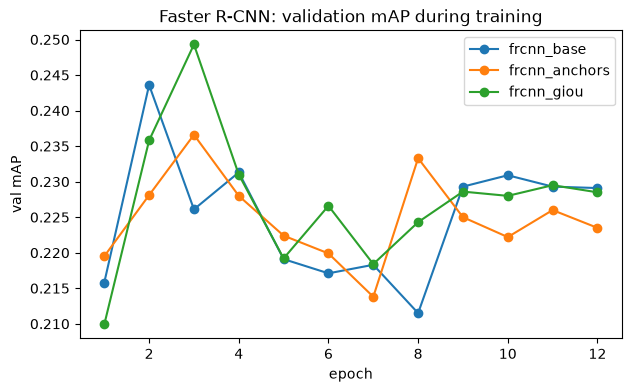

In [8]:
cols = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "ms_per_image", "anchors", "box_loss"]
frcnn = load_results().set_index("name").loc[["frcnn_base", "frcnn_anchors", "frcnn_giou"], cols]
display(frcnn)
fig, ax = plt.subplots(figsize=(7, 4))
for n in frcnn.index:
    h = pd.read_csv(PROJECT / "results" / f"{n}_history.csv"); ax.plot(h.epoch, h.mAP, marker="o", label=n)
ax.set_xlabel("epoch"); ax.set_ylabel("val mAP"); ax.legend(); ax.set_title("Faster R-CNN: validation mAP during training")
plt.show()

In [18]:
# Best Faster R-CNN (GIoU) on the test set -> Kaggle; compare its public score with the baseline (0.198)
model = tv.build_faster_rcnn()
model.load_state_dict(torch.load(CHECKPOINTS / "frcnn_giou_best.pt", map_location=DEVICE)); model.to(DEVICE)
test_preds = tv.predict(model, tv.test_items(test_df), DEVICE)
sub_path = PROJECT / "submissions" / "frcnn_giou.csv"
write_submission(test_preds, test_df, sub_path)
res_giou = json.load(open(PROJECT / "results" / "frcnn_giou.json"))
subprocess.run(["kaggle", "competitions", "submit", "-c", COMP, "-f", str(sub_path),
                "-m", f"Faster R-CNN GIoU, val mAP {res_giou['mAP']:.4f}"], check=True)

100%|██████████| 38.3M/38.3M [00:07<00:00, 5.65MB/s]


Submission ref: 58070439
3 submissions remaining today.
Successfully submitted to Multiple Object Video Detection | HW2 | UCU AI 2026

CompletedProcess(args=['kaggle', 'competitions', 'submit', '-c', 'multiple-object-video-detection-hw-2-ucu-ai-2026', '-f', '/home/julia/Documents/Yuliia/UCU/3/Artificial_intelligence/hw2/hw2-ai/submissions/frcnn_giou.csv', '-m', 'Faster R-CNN GIoU, val mAP 0.2493'], returncode=0)